# Colour scaling, normalization and terrain shading

Two fields with the same colormap can read completely differently depending on how values map to colours. cleopatra's `ColorScaling` group covers linear, power, symmetric-log, boundary and midpoint norms; Digital-Earth exposes them through the flat `color_scale=` keyword (plus `gamma`, `bounds`, `midpoint`). This notebook also shows `hillshade` for terrain relief.

In [1]:
%matplotlib inline
from pathlib import Path
import numpy as np
from pyramids.dataset import Dataset, GeoReference
from digitalearth.static import Map, grid

DATA = Path('../../../examples/data')   # notebook-relative path (docs/examples/presets -> repo root)
dem = Dataset.read_file(str(DATA / 'LisbonElevation.tif'))

# a strongly skewed positive field (a bright core over a faint background) where the scaling really matters
yy, xx = np.mgrid[0:120, 0:160]
blob = np.exp(-(((xx - 95)**2 + (yy - 45)**2) / (2 * 26**2)))
blob += 0.6 * np.exp(-(((xx - 55)**2 + (yy - 80)**2) / (2 * 18**2)))
skew = (blob * 5000 + 1).astype('float32')
GEO = (-180.0, 360 / 160, 0.0, 90.0, 0.0, -180 / 120)
skewed = Dataset.from_array(arr=skew, geo_ref=GeoReference(geo=GEO, epsg=4326))

## Linear vs power vs symmetric-log

On a skewed field a **linear** scale spends almost all its colour on the few large values and washes the rest out. **Power** (gamma) and **symmetric-log** scales redistribute the colour so the low-value structure reappears.

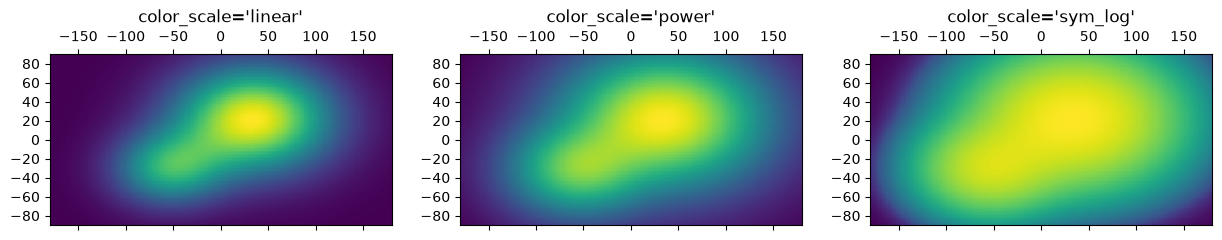

In [2]:
fig, maps = grid(1, 3, crs=4326, figsize=(15, 4))
for m, cs in zip(maps, ['linear', 'power', 'sym_log']):
    m.field(skewed, color_scale=cs, cmap='viridis'); m.set_title('color_scale=' + repr(cs))
fig;

`power` takes a `gamma` (below 1 lifts the low end); tune it directly.

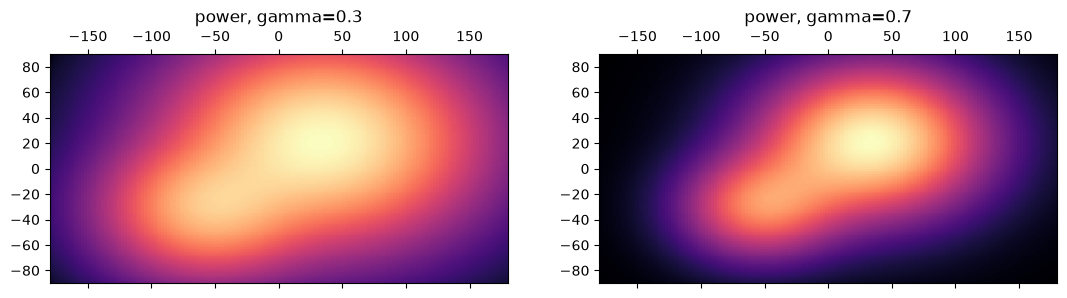

In [3]:
fig, maps = grid(1, 2, crs=4326, figsize=(13, 4))
maps[0].field(skewed, color_scale='power', gamma=0.3, cmap='magma'); maps[0].set_title('power, gamma=0.3')
maps[1].field(skewed, color_scale='power', gamma=0.7, cmap='magma'); maps[1].set_title('power, gamma=0.7')
fig;

## Midpoint normalization for diverging data

A diverging field should pin its neutral colour to a meaningful centre (usually zero). `color_scale='midpoint'` with `midpoint=` anchors the colormap there so positives and negatives stay balanced.

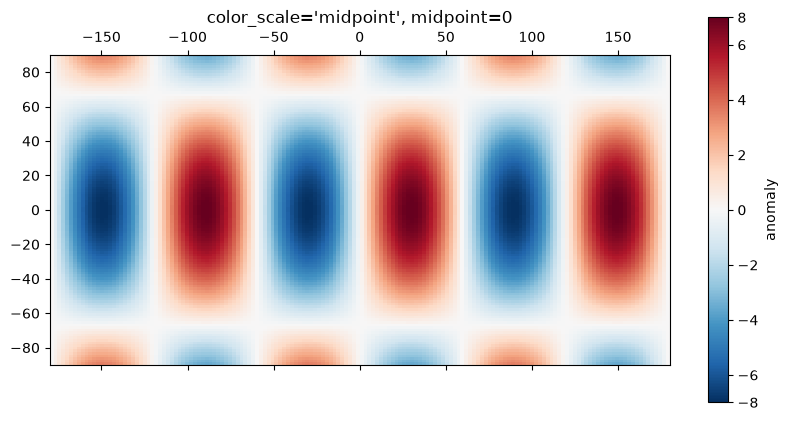

In [4]:
lat = np.linspace(60, -60, 120)[:, None]; lon = np.linspace(-180, 180, 160)[None, :]
anom = (7 * np.sin(np.deg2rad(3 * lon)) * np.cos(np.deg2rad(2 * lat))).astype('float32')
anomaly = Dataset.from_array(arr=anom, geo_ref=GeoReference(geo=GEO, epsg=4326))
m = Map(crs=4326, figsize=(10, 5))
m.field(anomaly, color_scale='midpoint', midpoint=0, cmap='RdBu_r')
m.colorbar(label='anomaly'); m.set_title("color_scale='midpoint', midpoint=0"); m.fig;

## Boundary norm - explicit class breaks

`color_scale='boundary'` with `bounds=[...]` maps values into discrete colour bands at breaks you choose - useful for legends with named classes.

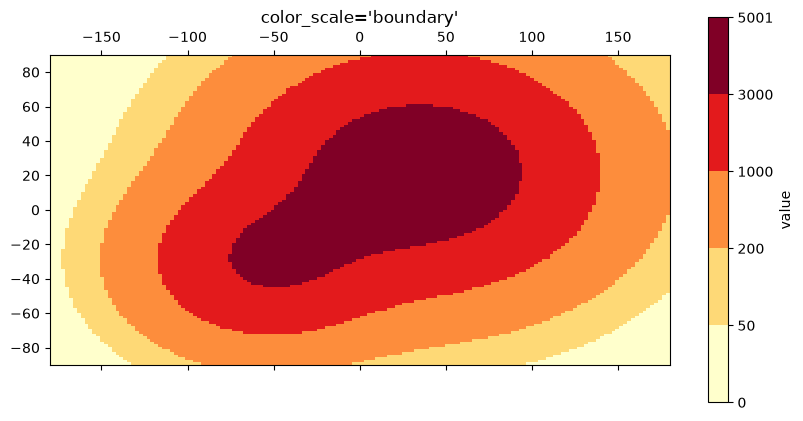

In [5]:
m = Map(crs=4326, figsize=(10, 5))
m.field(skewed, color_scale='boundary', bounds=[0, 50, 200, 1000, 3000, 5001], cmap='YlOrRd')
m.colorbar(label='value'); m.set_title("color_scale='boundary'"); m.fig;

## Terrain relief with `hillshade`

`hillshade=True` shades a raster by its slope and aspect. On its own it gives a grey relief; combined with an elevation preset it produces a shaded-relief elevation map.

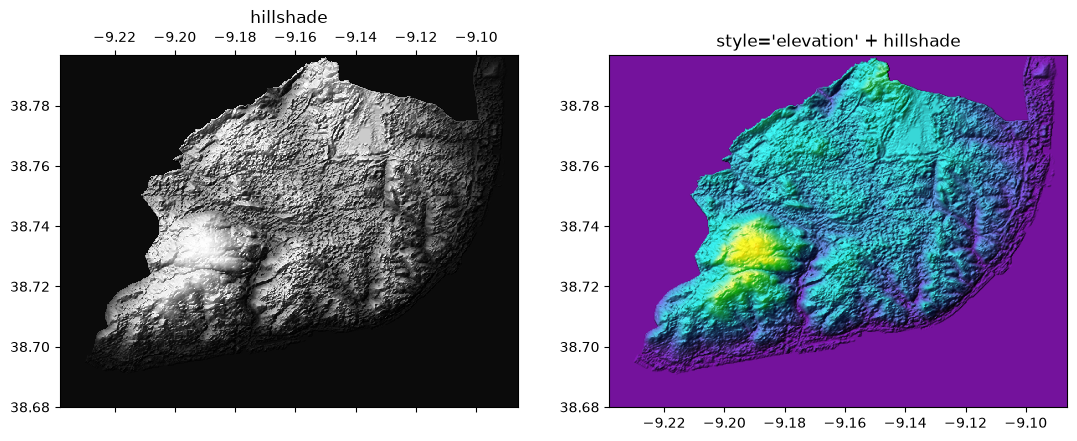

In [6]:
fig, maps = grid(1, 2, crs=dem.epsg, figsize=(13, 5))
maps[0].field(dem, hillshade=True, cmap='gray'); maps[0].set_title('hillshade')
maps[1].field(dem, style='elevation', hillshade=True); maps[1].set_title("style='elevation' + hillshade")
fig;